In [1]:
import os
import cv2
import random
import numpy as np
import pandas as pd

from tqdm import tqdm

import matplotlib.pyplot as plt

In [2]:
DATASET_PATH = r"D:\Multicrop Disease Dataset"

print(os.path.exists(DATASET_PATH))

True


In [3]:
image_extensions = (
    '.jpg',
    '.jpeg',
    '.png',
    '.bmp'
)

all_images = []

for root, dirs, files in os.walk(DATASET_PATH):

    for file in files:

        if file.lower().endswith(image_extensions):

            all_images.append(
                os.path.join(root, file)
            )

print("Total Images:", len(all_images))

Total Images: 21875


In [4]:
with open("tau_threshold.txt", "r") as f:

    tau = float(f.read())

print("Loaded τ =", tau)

Loaded τ = 41.3657885634315


In [5]:
sample_path = random.choice(all_images)

print(sample_path)

D:\Multicrop Disease Dataset\valid\images\Yellow-and-Black-Sigatoka-306-_jpg.rf.2b0e01acc75ed0fda2839cb8053d3850.jpg


In [6]:
import os

PAIR_ROOT = r"D:\ARTEN_Project\TrainingPairs"

INPUT_DIR = os.path.join(PAIR_ROOT, "input")
TARGET_DIR = os.path.join(PAIR_ROOT, "target")

os.makedirs(INPUT_DIR, exist_ok=True)
os.makedirs(TARGET_DIR, exist_ok=True)

print("Folders Created Successfully")

Folders Created Successfully


In [7]:
def motion_blur(image, kernel_size=15):

    kernel = np.zeros((kernel_size, kernel_size))

    kernel[int((kernel_size - 1)/2), :] = np.ones(kernel_size)

    kernel = kernel / kernel_size

    blurred = cv2.filter2D(
        image,
        -1,
        kernel
    )

    return blurred

In [8]:
def reduce_brightness(image):

    factor = random.uniform(
        0.4,
        0.8
    )

    image = image.astype(np.float32)

    image = image * factor

    image = np.clip(
        image,
        0,
        255
    )

    return image.astype(np.uint8)

In [9]:
def reduce_contrast(image):

    alpha = random.uniform(
        0.5,
        0.8
    )

    mean = np.mean(image)

    image = alpha * (image - mean) + mean

    image = np.clip(
        image,
        0,
        255
    )

    return image.astype(np.uint8)

In [10]:
def add_gaussian_noise(image):

    noise = np.random.normal(
        0,
        15,
        image.shape
    )

    image = image + noise

    image = np.clip(
        image,
        0,
        255
    )

    return image.astype(np.uint8)

In [11]:
def jpeg_compression(image, quality=30):

    encode_param = [
        int(cv2.IMWRITE_JPEG_QUALITY),
        quality
    ]

    _, encimg = cv2.imencode(
        '.jpg',
        image,
        encode_param
    )

    decimg = cv2.imdecode(
        encimg,
        1
    )

    return decimg

In [12]:
def generate_degradation(image):

    degraded = image.copy()

    if random.random() > 0.5:

        k = random.choice([3,5,7])

        degraded = cv2.GaussianBlur(
            degraded,
            (k,k),
            0
        )

    if random.random() > 0.5:

        degraded = motion_blur(
            degraded,
            random.choice([5,9,15])
        )

    if random.random() > 0.5:

        degraded = add_gaussian_noise(
            degraded
        )

    if random.random() > 0.5:

        degraded = reduce_brightness(
            degraded
        )

    if random.random() > 0.5:

        degraded = reduce_contrast(
            degraded
        )

    if random.random() > 0.5:

        degraded = jpeg_compression(
            degraded,
            quality=random.randint(20,50)
        )

    return degraded

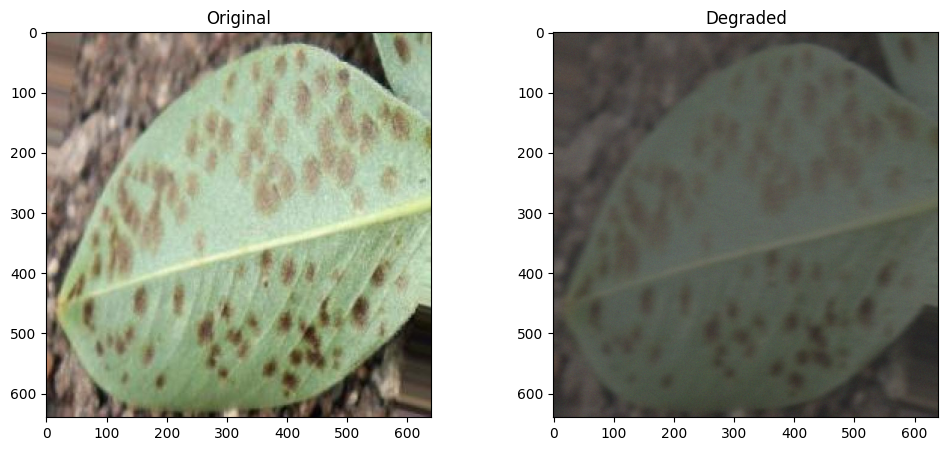

In [13]:
sample_path = random.choice(all_images)

img = cv2.imread(sample_path)

img = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

degraded = generate_degradation(img)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original")

plt.subplot(1,2,2)
plt.imshow(degraded)
plt.title("Degraded")

plt.show()

In [14]:
PAIR_COUNT = 3000

In [15]:
PAIR_COUNT = len(all_images)

In [16]:
selected_images = random.sample(
    all_images,
    PAIR_COUNT
)

print(
    "Selected Images:",
    len(selected_images)
)

Selected Images: 21875


In [17]:
from tqdm import tqdm

for idx, path in enumerate(
    tqdm(selected_images)
):

    img = cv2.imread(path)

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    img = cv2.resize(
        img,
        (256,256)
    )

    degraded = generate_degradation(img)

    filename = f"{idx:06d}.png"

    cv2.imwrite(
        os.path.join(
            INPUT_DIR,
            filename
        ),
        cv2.cvtColor(
            degraded,
            cv2.COLOR_RGB2BGR
        )
    )

    cv2.imwrite(
        os.path.join(
            TARGET_DIR,
            filename
        ),
        cv2.cvtColor(
            img,
            cv2.COLOR_RGB2BGR
        )
    )

print("Pair Generation Completed")

100%|████████████████████████████████████████████████████████████████████████████| 21875/21875 [04:29<00:00, 81.20it/s]

Pair Generation Completed


In [18]:
print(
    "Input Images:",
    len(os.listdir(INPUT_DIR))
)

print(
    "Target Images:",
    len(os.listdir(TARGET_DIR))
)

Input Images: 21875
Target Images: 21875


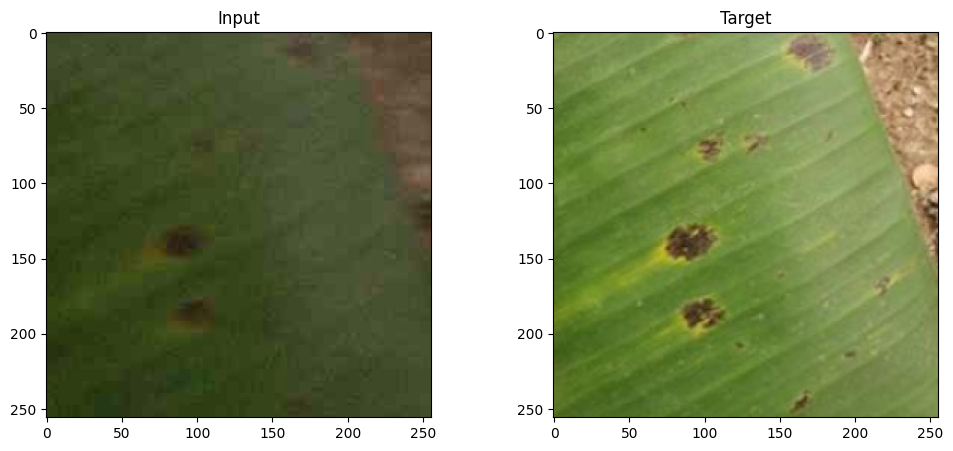

In [19]:
pair_id = random.randint(
    0,
    PAIR_COUNT-1
)

name = f"{pair_id:06d}.png"

inp = cv2.imread(
    os.path.join(
        INPUT_DIR,
        name
    )
)

tgt = cv2.imread(
    os.path.join(
        TARGET_DIR,
        name
    )
)

inp = cv2.cvtColor(
    inp,
    cv2.COLOR_BGR2RGB
)

tgt = cv2.cvtColor(
    tgt,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(inp)
plt.title("Input")

plt.subplot(1,2,2)
plt.imshow(tgt)
plt.title("Target")

plt.show()

In [20]:
pair_df = pd.DataFrame({

    "Pair_ID": list(range(PAIR_COUNT)),
    "Image_Path": selected_images

})

pair_df.to_csv(
    "training_pairs_metadata.csv",
    index=False
)

print("Metadata Saved")

Metadata Saved


In [21]:
print("="*50)

print("ARTEN Training Pair Generation Completed")

print("Total Pairs :", PAIR_COUNT)

print("Input Folder :", INPUT_DIR)

print("Target Folder :", TARGET_DIR)

print("="*50)

ARTEN Training Pair Generation Completed
Total Pairs : 21875
Input Folder : D:\ARTEN_Project\TrainingPairs\input
Target Folder : D:\ARTEN_Project\TrainingPairs\target
